In [3]:
#cell-1
import os
import random
import shutil
import timeit
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight



In [4]:
#cell-2
def create_sampled_dataset(source_dir, dest_dir, sample_size_per_class):
    """
    Create a smaller dataset by sampling a fixed number of images from each class.

    Args:
        source_dir (str): Path to the source dataset directory.
        dest_dir (str): Path to save the sampled dataset.
        sample_size_per_class (int): Number of images to sample per class.
    """
    if not os.path.exists(dest_dir):
        os.makedirs(dest_dir)

    class_names = ['0', '1', '2', '3', '4']
    for class_name in class_names:
        class_dir = os.path.join(source_dir, class_name)
        sampled_class_dir = os.path.join(dest_dir, class_name)

        if not os.path.exists(sampled_class_dir):
            os.makedirs(sampled_class_dir)

        images = os.listdir(class_dir)
        random.shuffle(images)

        sampled_images = images[:sample_size_per_class]
        for img in sampled_images:
            src_path = os.path.join(class_dir, img)
            dest_path = os.path.join(sampled_class_dir, img)
            shutil.copy(src_path, dest_path)


In [5]:
#cell-3
base_dir = "/content/extracted_files/dataset"
train_source_dir = os.path.join(base_dir, "train_split")
test_source_dir = os.path.join(base_dir, "test_split")

train_dest_dir = os.path.join(base_dir, "sampled_train")
test_dest_dir = os.path.join(base_dir, "sampled_test")

# Number of images per class to sample
sample_size_per_class = 1000  # Adjust this value as needed

# Create sampled datasets
create_sampled_dataset(train_source_dir, train_dest_dir, sample_size_per_class)
create_sampled_dataset(test_source_dir, test_dest_dir, sample_size_per_class)

print("Sampled dataset created.")



Sampled dataset created.


In [6]:
#cell-4
train_path = train_dest_dir
test_path = test_dest_dir

class_names = ['0', '1', '2', '3', '4']
target_size = (224, 224)
batch_size = 32

aug_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.inception_resnet_v2.preprocess_input,
    horizontal_flip=True,
    brightness_range=[0.3, 0.8],
    width_shift_range=[-50, 0, 50, 30, -30],
    zoom_range=0.1,
    fill_mode="nearest",
)
noaug_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.inception_resnet_v2.preprocess_input,
)

train_generator = aug_datagen.flow_from_directory(
    train_path, class_mode="categorical", target_size=target_size, shuffle=True
)
valid_generator = noaug_datagen.flow_from_directory(
    test_path, class_mode="categorical", target_size=target_size, shuffle=False,
)
y_train = train_generator.labels
y_val = valid_generator.labels

Found 3954 images belonging to 5 classes.
Found 2750 images belonging to 5 classes.


In [7]:
#cell-5
# Compute class weights
unique, counts = np.unique(y_train, return_counts=True)
print("Train: ", dict(zip(unique, counts)))
class_weights = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
train_class_weights = dict(enumerate(class_weights))
print("Class Weights: ", train_class_weights)

Train:  {0: 1000, 1: 1000, 2: 1000, 3: 777, 4: 177}
Class Weights:  {0: 0.7908, 1: 0.7908, 2: 0.7908, 3: 1.0177606177606178, 4: 4.467796610169492}


In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import DenseNet201

# Check GPU availability
device = "GPU" if tf.config.list_physical_devices('GPU') else "CPU"
print(f"Using {device} for training")

# Define the input shape for your model
img_shape = (224, 224, 3)  # Example: 224x224 RGB images

# Create the DenseNet201 model with ImageNet weights and without the top layer
base_model = DenseNet201(
    input_shape=img_shape,
    include_top=False,
    weights="imagenet"
)

# Make all layers trainable for fine-tuning
for layer in base_model.layers:
    layer.trainable = True

# Custom loss function to handle class weights
def weighted_categorical_crossentropy(class_weights):
    def loss_fn(y_true, y_pred):
        weights = tf.reduce_sum(class_weights * y_true, axis=-1)
        unweighted_losses = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
        weighted_losses = unweighted_losses * weights
        return tf.reduce_mean(weighted_losses)
    return loss_fn

# Provided class weights
train_class_weights = {0: 0.7908, 1: 0.7908, 2: 0.7908, 3: 1.0177606177606178, 4: 4.467796610169492}
class_weights_array = np.array([train_class_weights[i] for i in range(len(train_class_weights))])

# Create the final model
model = tf.keras.models.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(5, activation="softmax")  # 5 output classes for severity levels
])

# Define the custom loss function with class weights
loss_fn = weighted_categorical_crossentropy(class_weights_array)

# Compile the model
model.compile(
    optimizer="adam",
    loss=loss_fn,
    metrics=["accuracy"]
)

# Display model summary
model.summary()


Using GPU for training
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ densenet201 (Functional)             │ (None, 7, 7, 1920)          │      18,321,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1920)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1920)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 5)                   │           9,605 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18,331,589 (69.93 MB)

 Trainable params: 18,102,533 (69.06 MB)

 Non-trainable params: 229,056 (894.75 KB)

In [9]:
import timeit

# Callbacks
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)
plateau = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="loss", factor=0.1, patience=4, min_lr=1e-10
)

# Training the model
start_ft = timeit.default_timer()
history = model.fit(  # Replaced model_ft with model
    train_generator,
    epochs=50,  # Adjust based on your resources
    callbacks=[early, plateau],
    validation_data=valid_generator,
    class_weight=train_class_weights,
    verbose=1,
)
stop_ft = timeit.default_timer()

print(f"Training time: {stop_ft - start_ft:.2f} seconds")


Epoch 1/50


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


124/124 ━━━━━━━━━━━━━━━━━━━━ 792s 3s/step - accuracy: 0.2033 - loss: 1.8365 - val_accuracy: 0.3636 - val_loss: 7.5948 - learning_rate: 0.0010
Epoch 2/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 93s 728ms/step - accuracy: 0.3748 - loss: 1.1890 - val_accuracy: 0.1451 - val_loss: 9.5254 - learning_rate: 0.0010
Epoch 3/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 142s 733ms/step - accuracy: 0.4515 - loss: 1.0571 - val_accuracy: 0.1567 - val_loss: 5.9232 - learning_rate: 0.0010
Epoch 4/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 92s 720ms/step - accuracy: 0.4643 - loss: 1.0127 - val_accuracy: 0.3927 - val_loss: 3.1298 - learning_rate: 0.0010
Epoch 5/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 94s 725ms/step - accuracy: 0.5145 - loss: 0.9220 - val_accuracy: 0.4753 - val_loss: 1.6003 - learning_rate: 0.0010
Epoch 6/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 94s 726ms/step - accuracy: 0.5197 - loss: 0.9052 - val_accuracy: 0.5407 - val_loss: 1.0398 - learning_rate: 0.0010
Epoch 7/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 94s 726ms/step - accuracy: 0.5435 - loss: 

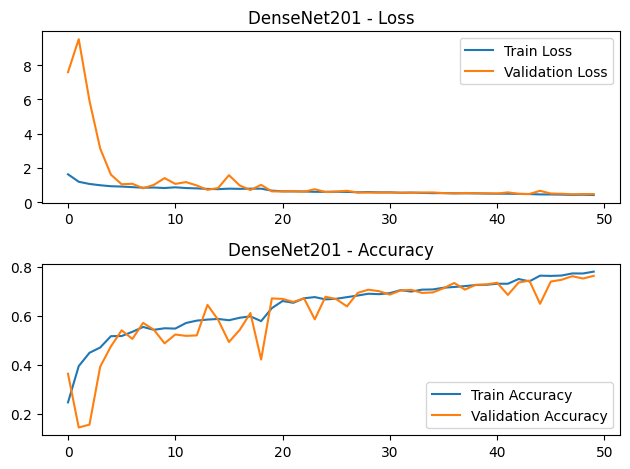

In [16]:
#cell-9
# Plot loss and accuracy
def get_plot_loss_acc(history, model_name):
    fig = plt.figure()
    plt.subplot(2, 1, 1)
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.legend()
    plt.title(f"{model_name} - Loss")

    plt.subplot(2, 1, 2)
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.legend()
    plt.title(f"{model_name} - Accuracy")
    plt.tight_layout()
    plt.show()

get_plot_loss_acc(history, "DenseNet201")


86/86 ━━━━━━━━━━━━━━━━━━━━ 11s 125ms/step - accuracy: 0.7825 - loss: 0.4322
Evaluation on Validation: Loss = 0.45289063453674316, Accuracy = 0.7610909342765808
86/86 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step
Model: DenseNet201
Accuracy: 0.7611
Balanced Accuracy: 0.8042

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.85      0.81      1000
           1       0.52      0.49      0.51       530
           2       0.84      0.69      0.76       757
           3       0.85      0.99      0.91       380
           4       0.99      1.00      0.99        83

    accuracy                           0.76      2750
   macro avg       0.79      0.80      0.80      2750
weighted avg       0.76      0.76      0.76      2750



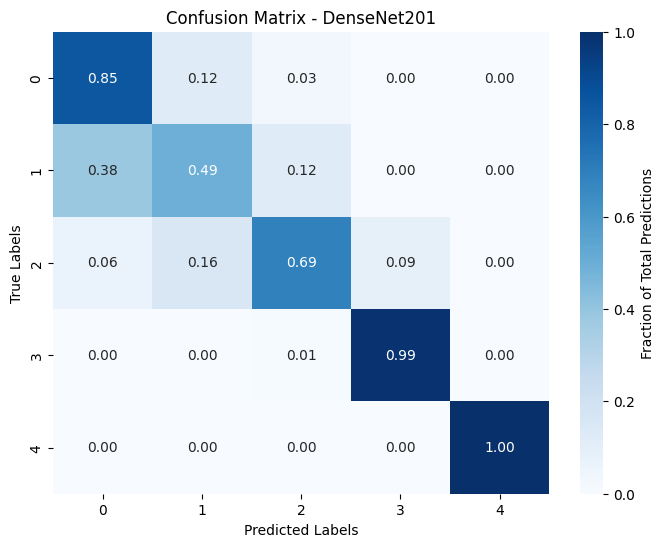

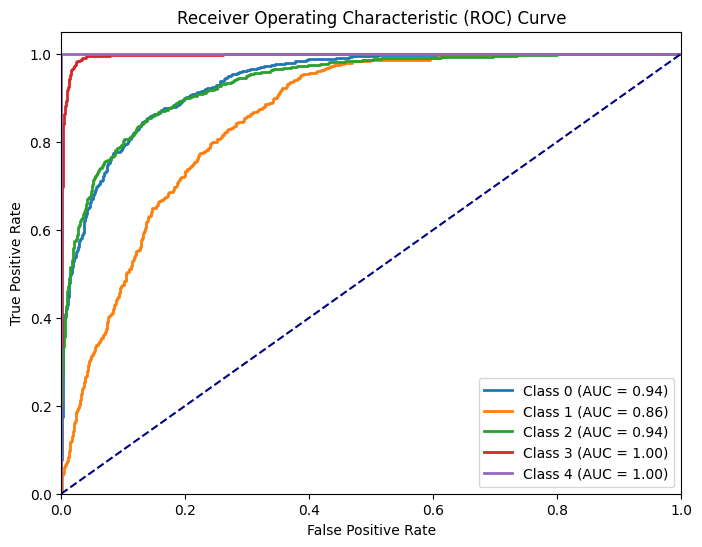

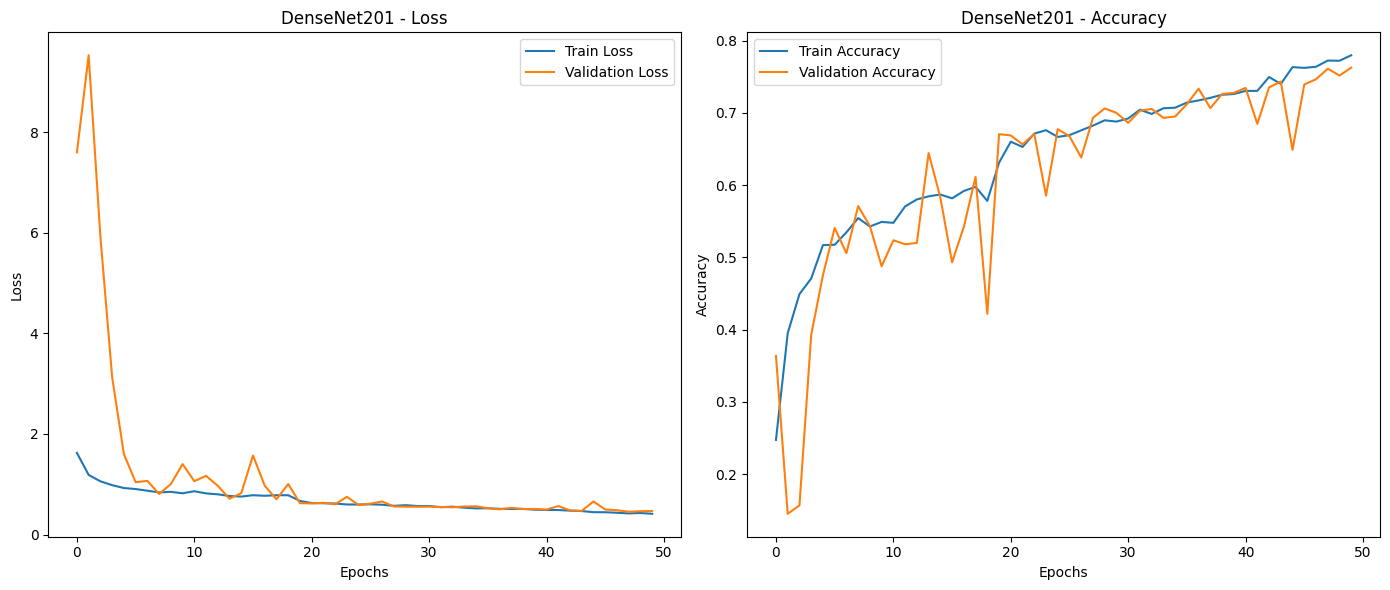

In [17]:
# Assign the model to model_ft if required
model_ft = model

# Evaluate the model
get_evaluate(valid_generator, "Validation", model_ft)

# Get predictions
y_pred = get_predict(valid_generator, model_ft)

# Get metrics
get_metrics(y_val, np.argmax(y_pred, axis=1), "DenseNet201")

# Plot Confusion Matrix
plot_confusion_matrix(y_val, np.argmax(y_pred, axis=1), "DenseNet201", class_names)

# Plot ROC Curve
plot_roc_curve(y_val, y_pred, class_names)

# Plot Loss and Accuracy
plot_loss_accuracy(history, "DenseNet201")


In [12]:
def get_evaluate(generator, dataset_name, model):
    loss, accuracy = model.evaluate(generator)
    print(f"Evaluation on {dataset_name}: Loss = {loss}, Accuracy = {accuracy}")

def get_predict(generator, model):
    predictions = model.predict(generator)
    return predictions

def get_metrics(y_true, y_pred, model_name):
    accuracy = accuracy_score(y_true, y_pred)
    balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

    print(f"Model: {model_name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

def plot_confusion_matrix(y_true, y_pred, model_name, class_names):
    cm = confusion_matrix(y_true, y_pred)
    cmn = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]  # Normalize by row

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names,
        cbar_kws={'label': 'Fraction of Total Predictions'}
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.ylabel("True Labels")
    plt.xlabel("Predicted Labels")
    plt.show()

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

def plot_roc_curve(y_true, y_pred, class_names):
    y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3, 4])
    fpr, tpr, roc_auc = dict(), dict(), dict()

    # Calculate ROC for each class
    for i in range(5):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Plot ROC curve
    plt.figure(figsize=(8, 6))
    for i in range(5):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"Class {class_names[i]} (AUC = {roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], color="navy", linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver Operating Characteristic (ROC) Curve")
    plt.legend(loc="lower right")
    plt.show()

def plot_loss_accuracy(history, model_name):
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))

    # Loss plot
    axs[0].plot(history.history["loss"], label="Train Loss")
    axs[0].plot(history.history["val_loss"], label="Validation Loss")
    axs[0].set_title(f"{model_name} - Loss")
    axs[0].set_xlabel("Epochs")
    axs[0].set_ylabel("Loss")
    axs[0].legend()

    # Accuracy plot
    axs[1].plot(history.history["accuracy"], label="Train Accuracy")
    axs[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
    axs[1].set_title(f"{model_name} - Accuracy")
    axs[1].set_xlabel("Epochs")
    axs[1].set_ylabel("Accuracy")
    axs[1].legend()

    plt.tight_layout()
    plt.show()


In [2]:
from google.colab import files

# Step 2: Unzip the file
!unzip -q dataset.zip -d /content/extracted_files/

# Step 3: Verify the extracted contents
!ls /content/extracted_files/



dataset
